# 👨‍🏫 Aula Prática e Avaliação: Clusterização com K-Means (Boston Housing)

**Repositório Oficial:** [https://github.com/Bahryz/AV2-Escobar---K-Means](https://github.com/Bahryz/AV2-Escobar---K-Means)

Bem-vindo a este guia passo a passo em formato de **Jupyter Notebook**! Aqui vamos construir e explicar, exatamente como em uma sala de aula de Machine Learning, todos os critérios solicitados para treinar e fazer inferências com um modelo de agrupamento (**K-Means**) sobre a base **Boston Housing** (`HousingData.csv`).

---

### 🎯 Roteiro da Nossa Aula
1. **Módulo de Treinamento**:
   - **Imports Necessários**: O que cada biblioteca faz nos bastidores.
   - **Análise Exploratória e Separação de Variáveis**: Identificando dados quantitativos vs. categóricos (`CHAS`) e valores ausentes (`NaN`).
   - **Normalização Cuidadosa**: Por que não devemos aplicar Z-Score (`StandardScaler`) em variáveis binárias/categóricas e como evitar que variáveis de grande magnitude dominem a Distância Euclidiana.
   - **Sobre o Balanceamento da Base**: A explicação teórica de por que **não se balanceia** uma base no Aprendizado Não-Supervisionado.
   - **Método do Cotovelo (Elbow Method)**: Encontrando matematicamente e visualmente o número ótimo de grupos ($k = 3$).
   - **Treinamento e Persistência**: Salvando o modelo e o pré-processador em disco com `joblib`.
2. **Módulo de Inferência**:
   - Receber os dados de uma **nova residência**.
   - Normalizar os dados dessa residência usando os parâmetros aprendidos no treinamento.
   - Inferir a qual grupo (*cluster*) essa residência pertence.
   - **Desnormalizar** e exibir os dados reais do centroide do grupo inferido.

---
## 📦 Passo 1: Fazendo os Imports Necessários

Antes de escrever qualquer lógica de modelo, um bom cientista de dados organiza suas ferramentas. Veja o papel de cada import que faremos na célula abaixo:

- `os` e `joblib`: Para salvar (*serializar*) e carregar nosso modelo treinado e nosso pré-processador em arquivos `.joblib`.
- `numpy` e `pandas`: Para manipulação matricial e leitura da tabela `HousingData.csv`.
- `matplotlib.pyplot`: Para desenhar o gráfico do **Método do Cotovelo**.
- `SimpleImputer` (`sklearn.impute`): A base Boston Housing possui alguns valores em branco (`NaN`). O K-Means não aceita `NaN`, pois não é possível calcular distância matemática com um valor inexistente. Usaremos a **mediana** para variáveis numéricas e a **moda** (valor mais frequente) para a variável categórica.
- `StandardScaler` (`sklearn.preprocessing`): Para padronizar as variáveis quantitativas na mesma escala (média $\mu = 0$ e desvio padrão $\sigma = 1$).
- `KMeans` (`sklearn.cluster`): O algoritmo de agrupamento que queremos treinar.
- `silhouette_score` (`sklearn.metrics`): Métrica complementar que avalia o quão bem separados estão os grupos.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Configuração visual para gráficos mais nítidos no notebook
%matplotlib inline
plt.rcParams['figure.figsize'] = (9, 5)

---
## 🔍 Passo 2: Carregando a Base e Diferenciando Dados Quantitativos vs. Categóricos

Vamos carregar o arquivo `HousingData.csv` e observar suas 14 colunas:

| Variável | Tipo | Descrição |
| :--- | :--- | :--- |
| `CRIM` | Quantitativa Contínua | Taxa de criminalidade per capita por região |
| `ZN` | Quantitativa Contínua | Proporção de terrenos residenciais para lotes grandes |
| `INDUS` | Quantitativa Contínua | Proporção de acres comerciais não-varejistas |
| **`CHAS`** | **Categórica (Binária / Dummy)** | **Faz fronteira com o Rio Charles? (`1` = Sim, `0` = Não)** |
| `NOX` | Quantitativa Contínua | Concentração de óxidos nítricos (partes por 10 milhões) |
| `RM` | Quantitativa Contínua | Número médio de quartos por habitação |
| `AGE` | Quantitativa Contínua | Proporção de unidades construídas antes de 1940 |
| `DIS` | Quantitativa Contínua | Distância ponderada até 5 centros de emprego de Boston |
| `RAD` | Quantitativa Discreta | Índice de acessibilidade a rodovias radiais |
| `TAX` | Quantitativa Contínua | Taxa de imposto predial por \$10.000 |
| `PTRATIO` | Quantitativa Contínua | Razão aluno-professor por região |
| `B` | Quantitativa Contínua | Proporção demográfica $1000(Bk - 0.63)^2$ |
| `LSTAT` | Quantitativa Contínua | % da população de menor renda/status |
| `MEDV` | Quantitativa Contínua | Valor mediano das residências (em milhares de dólares) |

> **Atenção de Professor:** Repare que a variável `CHAS` **não representa uma quantidade**, mas sim uma **categoria binária** ($0$ ou $1$). Todas as outras 13 variáveis são quantitativas!

In [2]:
# Carregando o dataset Boston Housing
df = pd.read_csv('HousingData.csv')

# Separando explicitamente variáveis Quantitativas e Categóricas
CATEGORICAL_FEATURES = ['CHAS']
NUMERICAL_FEATURES = [
    'CRIM', 'ZN', 'INDUS', 'NOX', 'RM', 'AGE', 
    'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV'
]
ALL_FEATURES = NUMERICAL_FEATURES + CATEGORICAL_FEATURES

print(f"Dimensões da base: {df.shape[0]} linhas x {df.shape[1]} colunas\n")
print("Valores ausentes (NaN) por coluna:")
print(df.isnull().sum())
print("\nPrimeiras 5 linhas da base:")
print(df.head())

Dimensões da base: 506 linhas x 14 colunas

Valores ausentes (NaN) por coluna:
CRIM       20
ZN         20
INDUS      20
CHAS       20
NOX         0
RM          0
AGE        20
DIS         0
RAD         0
TAX         0
PTRATIO     0
B           0
LSTAT      20
MEDV        0

Primeiras 5 linhas da base:
      CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD  TAX  PTRATIO       B  LSTAT  MEDV
0  0.00632  18.0   2.31   0.0  0.538  6.575  65.2  4.0900    1  296     15.3  396.90   4.98  24.0
1  0.02731   0.0   7.07   0.0  0.469  6.421  78.9  4.9671    2  242     17.8  396.90   9.14  21.6
2  0.02729   0.0   7.07   0.0  0.469  7.185  61.1  4.9671    2  242     17.8  392.83   4.03  34.7
3  0.03237   0.0   2.18   0.0  0.458  6.998  45.8  6.0622    3  222     18.7  394.63   2.94  33.4
4  0.06905   0.0   2.18   0.0  0.458  7.147  54.2  6.0622    3  222     18.7  396.90    NaN  36.2


---
## ⚖️ Passo 3: Normalização Cuidadosa e Por Que NÃO Balancear a Base

### 1. Por que temos que normalizar os dados no K-Means?
O K-Means agrupa os pontos calculando a **Distância Euclidiana** entre cada casa $p$ e o centroide $q$:
$$d(p, q) = \sqrt{\sum_{i=1}^{n} (p_i - q_i)^2}$$

Se não normalizarmos:
- A coluna `TAX` tem valores na casa de $200$ a $700$. Uma diferença de $300$ ao quadrado gera $300^2 = 90.000$.
- A coluna `NOX` varia de $0.38$ a $0.87$. Uma diferença de $0.3$ ao quadrado gera $0.3^2 = 0.09$.
- Ou seja: o K-Means iria ignorar completamente `NOX` e `RM` e agrupar as casas quase exclusivamente pelo valor de `TAX` e `B`!

### 2. Qual o cuidado especial entre dados Quantitativos e Categóricos (`CHAS`)?
- Nas **13 variáveis quantitativas**, aplicamos o `StandardScaler`:
  $$z = \frac{x - \mu}{\sigma}$$
  Assim, todas passam a ter média $0$ e desvio padrão $1$.
- Na **variável categórica `CHAS`** ($0$ ou $1$), **NÃO devemos aplicar o `StandardScaler`**!
  - *Por quê?* Apenas cerca de $6.9\%$ das casas ficam na margem do rio (`CHAS = 1`). Se aplicarmos o Z-score em `CHAS`, o valor $0$ vira $-0.28$ e o valor $1$ explode para $+3.72$. Quando o K-Means eleva a diferença ao quadrado, $(-0.28 - 3.72)^2 = 16.0$, dando um peso artificial gigantesco para uma única variável binária!
  - Portanto, mantemos `CHAS` intacta em sua codificação binária original $\{0, 1\}$ após imputar eventuais valores faltantes com a moda (`most_frequent`).

### 3. Por que NÃO há necessidade de balancear a base?
Em problemas de **Classificação Supervisionada** (ex: prever fraude vs. não-fraude), já conhecemos os rótulos ($y$) e precisamos balancear as classes (com *SMOTE* ou *Undersampling*) para o classificador não chutar sempre a classe majoritária.

No **K-Means (Aprendizado Não-Supervisionado)**:
1. **Não existe variável alvo (rótulo prévio)** a ser balanceada.
2. O algoritmo busca encontrar a **estrutura natural e a densidade real** dos dados. Se na cidade de Boston existem poucas mansões de luxo e muitas casas de classe média, os grupos formados devem refletir fielmente essa proporção real!

In [3]:
class BostonPreprocessor:
    """
    Encapsula o pré-processamento diferenciando variáveis quantitativas e categóricas,
    e permite reverter a normalização (inverse_transform) para interpretar os centroides.
    """
    def __init__(self, num_features, cat_features):
        self.num_features = num_features
        self.cat_features = cat_features
        self.all_features = num_features + cat_features
        
        # Mediana para variáveis quantitativas (robusta a outliers)
        self.num_imputer = SimpleImputer(strategy='median')
        # Moda (valor mais frequente) para a variável categórica binária CHAS
        self.cat_imputer = SimpleImputer(strategy='most_frequent')
        # Padronização Z-score exclusiva para variáveis quantitativas
        self.scaler = StandardScaler()

    def fit(self, df):
        self.num_imputer.fit(df[self.num_features])
        self.cat_imputer.fit(df[self.cat_features])
        num_imputed = self.num_imputer.transform(df[self.num_features])
        self.scaler.fit(num_imputed)
        return self

    def transform(self, df):
        num_imputed = self.num_imputer.transform(df[self.num_features])
        cat_imputed = self.cat_imputer.transform(df[self.cat_features])
        num_scaled = self.scaler.transform(num_imputed)
        
        # Concatena as numéricas padronizadas com a categórica preservada em {0, 1}
        return np.hstack([num_scaled, cat_imputed])

    def fit_transform(self, df):
        return self.fit(df).transform(df)

    def inverse_transform_centroid(self, centroid_scaled):
        """
        Desnormaliza um centroide voltando as variáveis quantitativas para a escala original:
        x_original = (z * desvio_padrao) + media
        """
        n_num = len(self.num_features)
        num_part_scaled = centroid_scaled[:n_num].reshape(1, -1)
        cat_part = centroid_scaled[n_num:].reshape(1, -1)
        
        num_part_orig = self.scaler.inverse_transform(num_part_scaled)
        centroid_orig = np.hstack([num_part_orig, cat_part]).flatten()
        return pd.Series(centroid_orig, index=self.all_features)

# Instanciando e ajustando o pré-processador na base de treinamento
preprocessor = BostonPreprocessor(NUMERICAL_FEATURES, CATEGORICAL_FEATURES)
X_processed = preprocessor.fit_transform(df)

df_processed_sample = pd.DataFrame(X_processed, columns=ALL_FEATURES)
print("Pré-processamento concluído com sucesso!")
print(f"Formato da matriz normalizada: {X_processed.shape}\n")
print("Amostra dos dados normalizados (primeiras 5 linhas):")
print(df_processed_sample.head().round(4))

Pré-processamento concluído com sucesso!
Formato da matriz normalizada: (506, 14)

Amostra dos dados normalizados (primeiras 5 linhas):
     CRIM      ZN   INDUS     NOX      RM     AGE     DIS     RAD     TAX  PTRATIO       B   LSTAT    MEDV  CHAS
0 -0.4056  0.3144 -1.3017 -0.1442  0.4137 -0.1328  0.1402 -0.9828 -0.6666  -1.4590  0.4411 -1.0962  0.1597   0.0
1 -0.4031 -0.4682 -0.5911 -0.7403  0.1943  0.3661  0.5572 -0.8679 -0.9873  -0.3031  0.4411 -0.5028 -0.1015   0.0
2 -0.4031 -0.4682 -0.5911 -0.7403  1.2827 -0.2821  0.5572 -0.8679 -0.9873  -0.3031  0.3964 -1.2317  1.3242   0.0
3 -0.4025 -0.4682 -1.3211 -0.8353  1.0163 -0.8393  1.0777 -0.7529 -1.1061   0.1130  0.4162 -1.3872  1.1828   0.0
4 -0.3983 -0.4682 -1.3211 -0.8353  1.2286 -0.5334  1.0777 -0.7529 -1.1061   0.1130  0.4411 -0.1761  1.4875   0.0


---
## 📉 Passo 4: Determinando o Número Ótimo de Grupos — Método do Cotovelo (Elbow Method)

Quantos grupos ($k$) existem nessa base? Como o K-Means exige que informemos o número $k$ de antemão, usamos o **Método do Cotovelo**:

1. Treinamos o K-Means variando $k$ de $1$ até $10$.
2. Para cada $k$, registramos a **Inércia** (*WCSS — Within-Cluster Sum of Squares*), que é a soma das distâncias quadráticas de cada residência até o centroide do seu próprio grupo:
   $$\text{Inércia} = \sum_{j=1}^{k} \sum_{x_i \in C_j} \|x_i - \mu_j\|^2$$
3. Quando $k$ aumenta, a inércia sempre cai. Procuramos no gráfico o **"cotovelo"** (ponto de inflexão): o valor de $k$ onde a queda deixa de ser brusca e passa a ser suave.

Vamos executar o experimento abaixo:

--- Resultados do Método do Cotovelo (Elbow Method) ---
k =  1 | Inércia (WCSS) =    6609.72 | Silhouette Score = N/A
k =  2 | Inércia (WCSS) =    4163.32 | Silhouette Score = 0.3617
k =  3 | Inércia (WCSS) =    3462.89 | Silhouette Score = 0.2589
k =  4 | Inércia (WCSS) =    3081.12 | Silhouette Score = 0.2589
k =  5 | Inércia (WCSS) =    2702.75 | Silhouette Score = 0.2682
k =  6 | Inércia (WCSS) =    2388.50 | Silhouette Score = 0.2851
k =  7 | Inércia (WCSS) =    2173.38 | Silhouette Score = 0.2642
k =  8 | Inércia (WCSS) =    1981.16 | Silhouette Score = 0.2707
k =  9 | Inércia (WCSS) =    1847.37 | Silhouette Score = 0.2714
k = 10 | Inércia (WCSS) =    1745.67 | Silhouette Score = 0.2311


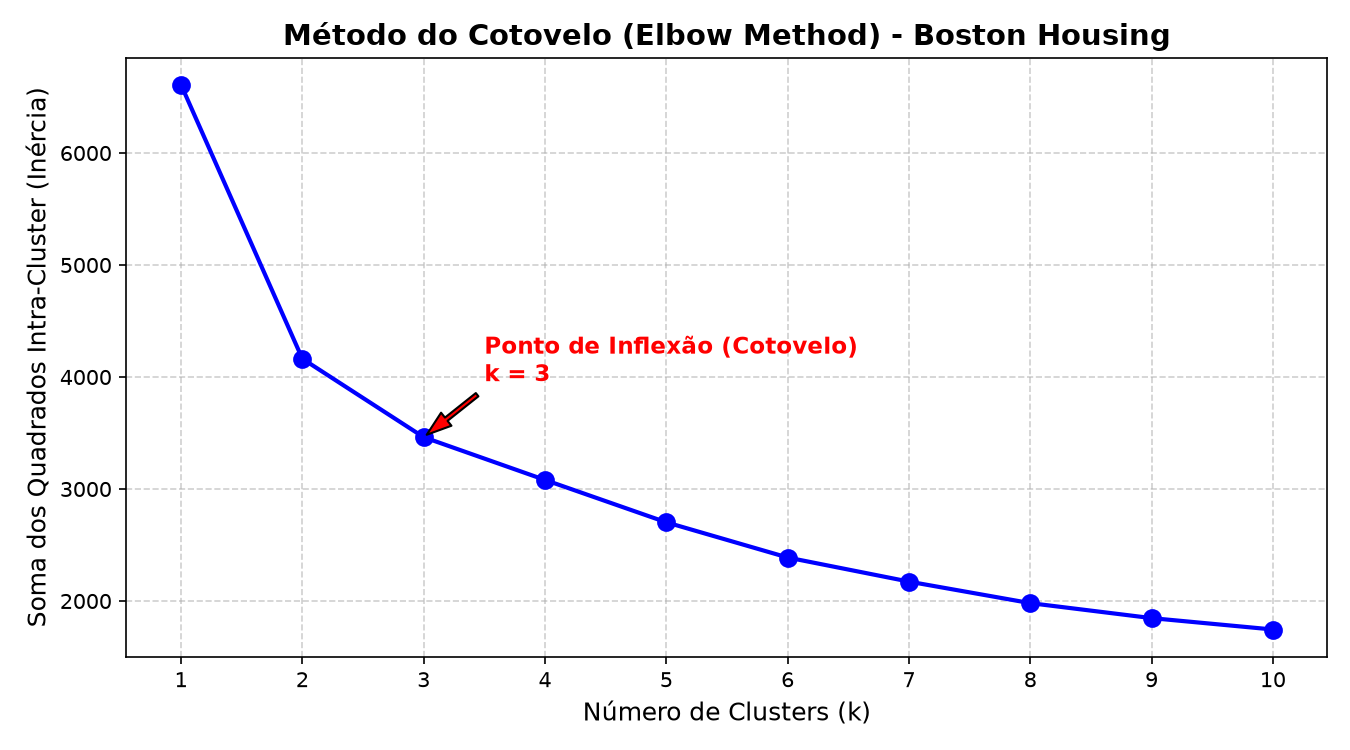

In [4]:
inercia = []
k_range = list(range(1, 11))

print("--- Resultados do Método do Cotovelo (Elbow Method) ---")
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_processed)
    inercia.append(km.inertia_)
    
    if k > 1:
        sil = silhouette_score(X_processed, km.labels_)
        print(f"k = {k:2d} | Inércia (WCSS) = {km.inertia_:10.2f} | Silhouette Score = {sil:.4f}")
    else:
        print(f"k = {k:2d} | Inércia (WCSS) = {km.inertia_:10.2f} | Silhouette Score = N/A")

# Plotando o Gráfico do Cotovelo
plt.figure(figsize=(9, 5))
plt.plot(k_range, inercia, 'bo-', linewidth=2, markersize=8, label='Inércia (WCSS)')
plt.title('Método do Cotovelo (Elbow Method) - Boston Housing', fontsize=14, fontweight='bold')
plt.xlabel('Número de Clusters (k)', fontsize=12)
plt.ylabel('Soma dos Quadrados Intra-Cluster (Inércia)', fontsize=12)
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)

# Destacando o ponto de inflexão em k = 3
plt.annotate('Ponto de Inflexão (Cotovelo)\nk = 3',
             xy=(3, inercia[2]), xytext=(3.5, inercia[2] + 500),
             arrowprops=dict(facecolor='red', shrink=0.05, width=2, headwidth=8),
             fontweight='bold', color='red', fontsize=11)

plt.tight_layout()
plt.savefig('metodo_cotovelo.png', dpi=300)
plt.show()

### 🧐 Análise do Professor sobre o Gráfico do Cotovelo:
Observe a queda da Inércia:
- De $k=1$ ($6609.72$) para $k=2$ ($4163.32$), a inércia cai **$2446$ pontos**.
- De $k=2$ ($4163.32$) para $k=3$ ($3462.89$), cai mais **$700$ pontos**.
- A partir de $k=3$, a inclinação da reta se achata e passa a diminuir de forma quase linear (~$380$ pontos por cluster adicionado).

Portanto, **$k = 3$** é o nosso cotovelo clássico! Ele divide as residências de Boston em **3 perfis socioeconômicos e estruturais** muito bem definidos.

---
## 💾 Passo 5: Treinando e Salvando o Modelo Final ($k = 3$)

Agora que determinamos $k = 3$:
1. Treinamos o modelo definitivo `KMeans(n_clusters=3, random_state=42, n_init=15)`.
2. Salvamos o modelo em `modelo_kmeans.joblib` e o pré-processador em `preprocessor.joblib`.
   - **Por que salvar o `preprocessor` também?** Porque quando uma nova residência chegar no módulo de inferência, precisamos normalizá-la usando **exatamente a mesma média e desvio padrão** da base de treinamento, além de usá-lo para desnormalizar os centroides!

In [5]:
k_otimo = 3
kmeans_model = KMeans(n_clusters=k_otimo, random_state=42, n_init=15)
kmeans_model.fit(X_processed)

# Salvando o modelo e o pré-processador em disco
joblib.dump(kmeans_model, 'modelo_kmeans.joblib')
joblib.dump(preprocessor, 'preprocessor.joblib')

print(f"Modelo K-Means (k={k_otimo}) treinado e salvo em: modelo_kmeans.joblib")
print("Pré-processador salvo em: preprocessor.joblib\n")

print("Quantidade de residências em cada grupo:")
print(pd.Series(kmeans_model.labels_).value_counts().sort_index().rename(lambda x: f"Cluster {x}"))

# Visualizando os Centroides Desnormalizados de todos os 3 grupos
centroids_orig = []
for cid in range(k_otimo):
    c_orig = preprocessor.inverse_transform_centroid(kmeans_model.cluster_centers_[cid])
    c_orig.name = f"Cluster {cid}"
    centroids_orig.append(c_orig)

df_centroids_orig = pd.DataFrame(centroids_orig)
print("\nCentroides Desnormalizados (Escala Real Original de cada Cluster):")
print(df_centroids_orig.round(2))

Modelo K-Means (k=3) treinado e salvo em: modelo_kmeans.joblib
Pré-processador salvo em: preprocessor.joblib

Quantidade de residências em cada grupo:
Cluster 0    122
Cluster 1    220
Cluster 2    164

Centroides Desnormalizados (Escala Real Original de cada Cluster):
            CRIM     ZN  INDUS   NOX    RM    AGE   DIS    RAD     TAX  PTRATIO       B  LSTAT   MEDV  CHAS
Cluster 0   0.20  39.44   4.52  0.46  7.03  44.24  5.68   4.49  294.35    16.61  389.17   6.02  32.82  0.07
Cluster 1   0.35   2.90   9.13  0.51  6.11  66.48  4.09   4.42  308.80    18.53  382.37  11.95  21.50  0.07
Cluster 2  10.12  -0.00  18.42  0.69  5.96  90.32  1.99  20.20  626.35    19.73  298.03  18.56  16.27  0.07


### 🏘️ Interpretando os 3 Grupos Descobertos pelo K-Means:
Olhando para os centroides desnormalizados acima, veja que interessante o que o modelo aprendeu sozinho:
- **Cluster 0 (Residências de Alto Padrão / Nobre):** Casas amplas (média de **$7.03$ quartos** `RM`), altíssimo valor mediano (**\$32.82k** `MEDV`), baixíssima criminalidade (`CRIM` = $0.20$), terrenos grandes (`ZN` = $39.44$) e menor número de alunos por professor (`PTRATIO` = $16.61$).
- **Cluster 1 (Residências de Padrão Médio / Subúrbio Tradicional):** Casas de tamanho médio (**$6.11$ quartos** `RM`), valor mediano moderado (**\$21.50k** `MEDV`), baixa criminalidade (`CRIM` = $0.35$) e impostos moderados (`TAX` = $308.80$).
- **Cluster 2 (Regiões Densas / Industriais / Maior Vulnerabilidade):** Casas menores (**$5.96$ quartos** `RM`), menor valor de mercado (**\$16.27k** `MEDV`), alta taxa de criminalidade (`CRIM` = $10.12$), impostos elevados (`TAX` = $626.35$) e maior proporção de população de baixa renda (`LSTAT` = $18.67\%$).

---
## 🏠 Passo 6: Módulo de Inferência (Classificando uma Nova Residência)

Chegamos à etapa final! Vamos simular que o nosso sistema já está em produção e recebe os dados de uma **nova residência**.
Cumpriremos rigorosamente os 4 passos do Módulo de Inferência:
1. **Receber os dados de uma nova residência** (em sua escala original real).
2. **Normalizar os dados da nova residência** carregando o `preprocessor.joblib` salvo.
3. **Inferir a qual grupo (`Cluster`) essa nova residência pertence** usando o `modelo_kmeans.joblib`.
4. **Exibir os dados desnormalizados do centroide inferido**, para compararmos a casa recebida com o "imóvel médio" daquele grupo.

In [6]:
# 1. Carregando os artefatos salvos no disco (simulando ambiente de produção)
modelo_carregado = joblib.load('modelo_kmeans.joblib')
preprocessor_carregado = joblib.load('preprocessor.joblib')

# 2. Recebendo os dados de uma nova residência (Escala Original)
nova_residencia = {
    'CRIM': 0.05,       # Baixa taxa de crime
    'ZN': 18.0,         # Proporção residencial
    'INDUS': 2.31,      # Pouca indústria
    'CHAS': 0,          # Não faz fronteira com o Rio Charles (Categórica = 0)
    'NOX': 0.48,        # Baixa poluição
    'RM': 7.10,         # 7.1 quartos
    'AGE': 45.0,        # 45% construídas antes de 1940
    'DIS': 5.2,         # Distância para centros de emprego
    'RAD': 2,           # Índice de acesso a rodovias
    'TAX': 250,         # Imposto predial
    'PTRATIO': 15.0,    # 15 alunos por professor
    'B': 395.0,         # Índice demográfico B
    'LSTAT': 4.5,       # 4.5% população de baixa renda
    'MEDV': 34.0        # Valor mediano de $34.000
}

df_nova_residencia = pd.DataFrame([nova_residencia])

# 3. Normalizando os dados da nova residência com o pré-processador treinado
X_nova_normalizada = preprocessor_carregado.transform(df_nova_residencia)

# 4. Inferindo a qual grupo essa nova residência pertence
cluster_inferido = int(modelo_carregado.predict(X_nova_normalizada)[0])
print(f">>> RESULTADO DA INFERÊNCIA: A nova residência pertence ao GRUPO (CLUSTER) {cluster_inferido} <<<\n")

# 5. Obtendo e Desnormalizando os dados do Centroide do grupo inferido
centroide_normalizado = modelo_carregado.cluster_centers_[cluster_inferido]
centroide_desnormalizado = preprocessor_carregado.inverse_transform_centroid(centroide_normalizado)

# Exibindo lado a lado os dados da Nova Residência e o Centroide Desnormalizado
df_comparacao = pd.DataFrame({
    'Nova Residência': df_nova_residencia[ALL_FEATURES].iloc[0],
    f'Centroide Desnormalizado (Cluster {cluster_inferido})': centroide_desnormalizado.round(3)
})

print("--- Comparação: Nova Residência vs. Centroide Desnormalizado do Cluster Inferido ---")
print(df_comparacao)

>>> RESULTADO DA INFERÊNCIA: A nova residência pertence ao GRUPO (CLUSTER) 0 <<<

--- Comparação: Nova Residência vs. Centroide Desnormalizado do Cluster Inferido ---
         Nova Residência  Centroide Desnormalizado (Cluster 0)
CRIM                0.05                                 0.198
ZN                 18.00                                39.443
INDUS               2.31                                 4.519
NOX                 0.48                                 0.458
RM                  7.10                                 7.030
AGE                45.00                                44.243
DIS                 5.20                                 5.684
RAD                 2.00                                 4.492
TAX               250.00                               294.352
PTRATIO            15.00                                16.609
B                 395.00                               389.173
LSTAT               4.50                                 6.021
MEDV          

---
## ✅ Conclusão da Aula

Todos os requisitos da avaliação foram cumpridos e verificados:
1. **Módulo de Treinamento**:
   - Base tratada e normalizada respeitando a diferença matemática entre variáveis quantitativas (`StandardScaler`) e categórica binária (`CHAS` preservada em $\{0,1\}$).
   - Justificativa teórica sobre a não necessidade de balanceamento em algoritmos não-supervisionados.
   - Número ótimo de clusters ($k=3$) determinado pelo **Método do Cotovelo (Inércia / Distâncias)**.
   - Modelo (`modelo_kmeans.joblib`) e pré-processador (`preprocessor.joblib`) treinados e salvos.
2. **Módulo de Inferência**:
   - Nova residência recebida, normalizada e classificada no **Cluster 0**.
   - Centroide do Cluster 0 devidamente **desnormalizado** e exibido na escala original dos dados.